## Grafos y comunidades: Grafo

- Se define el grafo en el que se buscan comunidades (nodos, aristas, peso)

- **Núcleo** sobre el que corren los algoritmos locales

- Spark para las estadísticas del grafo completo (60k nodos, 1.6M aristas) y los atributos de los proveedores

- Scipy para componentes y el barrido de filtros; matriz dispersa del grafo completo no cabe

### Constantes

- `RANGO_MIN_COP`: mínimo de procesos compartidos para conservar una arista

- `RANGO_TOPE`: percentil de grado desde el que un proveedor es hub y se le retira

- `RANGO_PESO`: pesos de arista que se comparan

In [1]:
RANGO_MIN_COP = [2, 3, 4, 5, 7, 10, 15, 20]
RANGO_TOPE = [None, 0.999, 0.99, 0.95]
RANGO_PESO = ["binario", "n_coparticipa", "peso"]

### Utilidades

In [2]:
NOTEBOOK = "a_grafo"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

- `grafo_coparticipacion`: arista entre dos proveedores que compiten en ≥ 2 procesos de 2 a 30 postores 

- `n_coparticipa` y `peso` = Σ 1/(n − 1)

In [4]:
v_s = leer(artef_dir, "grafo_coparticipacion/vertices").cache()
a_s = leer(artef_dir, "grafo_coparticipacion/aristas").where("src != dst").cache()
print(f"vértices: {v_s.count():,} | aristas: {a_s.count():,}")

vértices: 60,213 | aristas: 1,639,945


In [5]:
inversas = (a_s.alias("x").join(a_s.alias("y"), (F.col("x.src") == F.col("y.dst")) & (F.col("x.dst") == F.col("y.src")))
               .count())
dobles = inversas > 0
if dobles:
    a_s = a_s.where("src < dst").cache()
print(f"aristas guardadas en ambos sentidos: {'sí' if dobles else 'no'} | aristas no dirigidas: {a_s.count():,}")

aristas guardadas en ambos sentidos: no | aristas no dirigidas: 1,639,945


- Se trabaja con una fila por par: el grafo es **no dirigido** (competir es simétrico)

---
### **1. Estructura del grafo**

Aristas son pares (i,j) del grafo

In [6]:
lado = lambda c: a_s.select(F.col(c).alias("id"), "n_coparticipa", "peso")
grados = (lado("src").unionByName(lado("dst")).groupBy("id")
            .agg(F.count("*").alias("grado"), F.sum("peso").alias("fuerza"))
            .join(v_s.select("id", "es_consorcio"), "id", "right").fillna(0, ["grado", "fuerza"]).cache())
n, m = grados.count(), a_s.count()
q = grados.where("grado > 0").approxQuantile("grado", [.5, .9, .99, 1.0], .001)
qc = a_s.approxQuantile("n_coparticipa", [.5, .9, .99], .001)
resumen = pd.DataFrame([
    ("nodos", n), ("aristas", m), ("densidad", 2 * m / (n * (n - 1))),
    ("nodos aislados", grados.where("grado = 0").count()),
    ("grado p50", q[0]), ("grado p90", q[1]), ("grado p99", q[2]), ("grado máximo", q[3]),
    ("n_coparticipa p50", qc[0]), ("n_coparticipa p90", qc[1]), ("n_coparticipa p99", qc[2]),
    ("% aristas con 2 procesos (el mínimo)", 100 * a_s.where("n_coparticipa = 2").count() / m),
    ("% nodos consorcio", 100 * grados.where("es_consorcio = 1").count() / n)], columns=["medida", "valor"])
resumen

,medida,valor
0,nodos,6.021300e+04
1,aristas,1.639945e+06
2,densidad,9.046612e-04
3,nodos aislados,0.000000e+00
4,grado p50,1.700000e+01
5,grado p90,1.200000e+02
6,grado p99,5.290000e+02
7,grado máximo,1.205900e+04
8,n_coparticipa p50,3.000000e+00
9,n_coparticipa p90,9.000000e+00


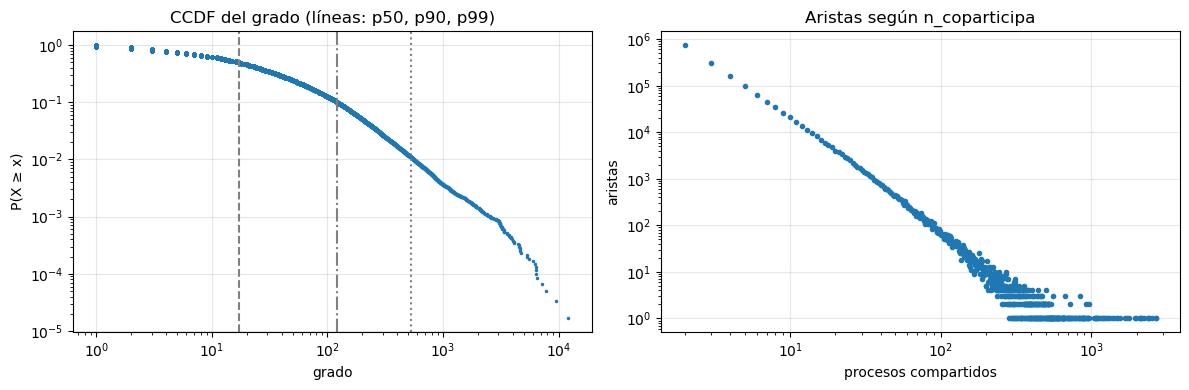

In [7]:
g = grados.select("grado", "es_consorcio").toPandas()
cop = a_s.groupBy("n_coparticipa").count().toPandas().sort_values("n_coparticipa")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
x = np.sort(g.grado[g.grado > 0].to_numpy())
ax[0].loglog(x, 1 - np.arange(len(x)) / len(x), ".", ms=3)
for p, ls in zip(q[:3], ("--", "-.", ":")):
    ax[0].axvline(p, ls=ls, c="gray")
ax[0].set(xlabel="grado", ylabel="P(X ≥ x)", title="CCDF del grado (líneas: p50, p90, p99)")
ax[1].loglog(cop.n_coparticipa, cop["count"], "o", ms=3)
ax[1].set(xlabel="procesos compartidos", ylabel="aristas", title="Aristas según n_coparticipa")
mostrar_fig("estructura_grafo")

- **Cola muy pesada:** grado mediano **17**, p99 **528** y máximo **12,059**

- Puñado de proveedores compite con una fracción enorme del resto

- **Esos hubs** se presentan a todo (bienes comunes, alcance nacional)

- **El 45.7%** de las aristas son de solo 2 procesos compartidos (mediana 3)

- Coincidencias débiles, candidatas a filtrarse

---
### **2. Atributos de los proveedores**

- La dirección del proveedor no está en la fuente: se usa la **región dominante** de los procesos en que participa

- **Categoría** (bienes, servicios, obras) dominante de sus participaciones y **familia** dominante de sus adjudicaciones

In [8]:
def moda(df, clave, col, nombre):
    w = Window.partitionBy(clave).orderBy(F.desc("n"), F.asc(col))
    tot = Window.partitionBy(clave)
    return (df.where(F.col(col).isNotNull()).groupBy(clave, col).agg(F.count("*").alias("n"))
              .withColumn("cuota", F.col("n") / F.sum("n").over(tot))
              .withColumn("r", F.row_number().over(w)).where("r = 1")
              .select(clave, F.col(col).alias(nombre), F.col("cuota").alias(f"cuota_{nombre}")))

part = leer(final_dir, "participantes").select("ocid", "proveedor_key", "gano")
proc = leer(final_dir, "procesos").select("ocid", "region", "categoria")
pp = part.join(proc, "ocid").cache()
atrib = (pp.groupBy("proveedor_key")
           .agg(F.count("*").alias("participaciones"), F.sum(F.col("gano").cast("int")).alias("ganados"),
                F.countDistinct("region").alias("n_regiones"))
           .join(moda(pp, "proveedor_key", "region", "region_dom"), "proveedor_key", "left")
           .join(moda(pp, "proveedor_key", "categoria", "categoria_dom"), "proveedor_key", "left")
           .join(moda(leer(final_dir, "hechos"), "proveedor_key", "familia", "familia_dom"), "proveedor_key", "left"))
nodos_s = v_s.select("id", "nombre", "es_consorcio", F.expr("substring(id, 3)").alias("clave"))
at = nodos_s.join(atrib, nodos_s.clave == atrib.proveedor_key, "left").drop("proveedor_key").toPandas()
print(f"{len(at):,} proveedores | con región dominante: {at.region_dom.notna().mean():.1%}")

60,213 proveedores | con región dominante: 100.0%


,medida,valor
0,% con región dominante,100.000000
1,% mono-regional (≥ 80% en una región),54.023218
2,% con categoría dominante,100.000000
3,% con familia (ganó alguna vez),45.076645
4,regiones distintas,25.000000
5,familias distintas,331.000000


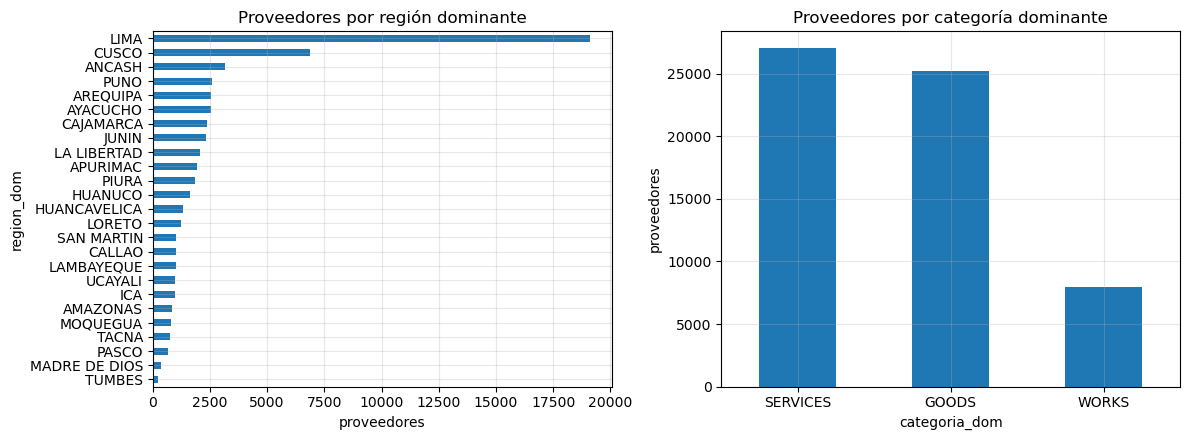

In [9]:
cobertura = pd.DataFrame([
    ("% con región dominante", 100 * at.region_dom.notna().mean()),
    ("% mono-regional (≥ 80% en una región)", 100 * (at.cuota_region_dom >= .8).mean()),
    ("% con categoría dominante", 100 * at.categoria_dom.notna().mean()),
    ("% con familia (ganó alguna vez)", 100 * at.familia_dom.notna().mean()),
    ("regiones distintas", at.region_dom.nunique()), ("familias distintas", at.familia_dom.nunique())],
    columns=["medida", "valor"])
display(cobertura)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
at.region_dom.value_counts().plot.barh(ax=ax[0]); ax[0].invert_yaxis()
ax[0].set(title="Proveedores por región dominante", xlabel="proveedores")
at.categoria_dom.value_counts().plot.bar(ax=ax[1], rot=0)
ax[1].set(title="Proveedores por categoría dominante", ylabel="proveedores")
mostrar_fig("atributos_proveedores")

- **54.0%** de los proveedores tiene ≥ 80% de sus participaciones en una región

- Si las comunidades siguen la geografía, la región dominante debería explicarlas

- La categoría es gruesa (3 valores) y la familia solo existe para quien ganó alguna vez

---
### **3. Núcleo para los algoritmos**

- Espectral, BigCLAM y Louvain en networkx necesitan el grafo en memoria y crecen más que lineal

- 1.6M aristas y hubs de grado **12,059** no caben

- **Núcleo:** se retiran los hubs (grado ≥ percentil) y las aristas con menos de `min_cop` procesos compartidos

- Se toma la componente gigante

In [10]:
v = pd.read_parquet(artef_dir / "grafo_coparticipacion" / "vertices", columns=["id"]).sort_values("id", ignore_index=True)
a = pd.read_parquet(artef_dir / "grafo_coparticipacion" / "aristas", columns=["src", "dst", "n_coparticipa", "peso"])
a = a[a.src != a.dst]
if dobles:
    a = a[a.src < a.dst]
pos = pd.Series(np.arange(len(v)), index=v.id)
a = a.assign(i=a.src.map(pos), j=a.dst.map(pos)).reset_index(drop=True)
assert a[["i", "j"]].notna().all().all(), "hay aristas con extremos fuera de los vértices"
a = a.astype({"i": int, "j": int})
grado = np.bincount(np.r_[a.i, a.j], minlength=len(v))
print(f"local: {len(v):,} nodos | {len(a):,} aristas")

local: 60,213 nodos | 1,639,945 aristas


In [11]:
def nucleo(min_cop, tope):
    hub = np.zeros(len(v), bool) if tope is None else grado >= np.quantile(grado[grado > 0], tope)
    e = a[(a.n_coparticipa >= min_cop).to_numpy() & ~hub[a.i.to_numpy()] & ~hub[a.j.to_numpy()]]
    gig = gigante(matriz(e, len(v), "binario"))
    return hub, e[gig[e.i.to_numpy()]], gig

barrido = []
for tope in RANGO_TOPE:
    for min_cop in RANGO_MIN_COP:
        hub, e, gig = nucleo(min_cop, tope)
        barrido.append({"tope": "sin tope" if tope is None else str(tope), "min_cop": min_cop, "hubs": int(hub.sum()),
                        "nodos": int(gig.sum()), "aristas": len(e), "pct_nodos": 100 * gig.sum() / len(v),
                        "pct_peso": 100 * e.peso.sum() / a.peso.sum(),
                        "grado_max": int(np.bincount(np.r_[e.i, e.j]).max()) if len(e) else 0})
barrido = pd.DataFrame(barrido)
barrido["viable"] = barrido.nodos.between(N_MIN, N_MAX) & (barrido.aristas <= E_MAX)
display(barrido)

part_barrido = []
for r in barrido[barrido.viable].itertuples():
    tope_r = None if r.tope == "sin tope" else float(r.tope)
    _, e_b, gig_b = nucleo(r.min_cop, tope_r)
    idx_b = np.flatnonzero(gig_b)
    mapa_b = pd.Series(np.arange(len(idx_b)), index=idx_b)
    e_b = e_b.assign(i=mapa_b[e_b.i].to_numpy(), j=mapa_b[e_b.j].to_numpy())
    lab_b = louvain(a_networkx(matriz(e_b, len(idx_b), "peso")), 1.0)          # γ = 1 fijo
    part_barrido.append(pd.DataFrame({"clave": v.id.iloc[idx_b].str[2:].to_numpy(),   # = substring(id, 3)
                                      "min_cop": r.min_cop, "tope": r.tope,
                                      "comunidad": np.asarray(lab_b)}))
pd.concat(part_barrido, ignore_index=True).to_parquet(datos_dir / "particion_barrido.parquet", index=False)
print(f"particiones guardadas para {len(part_barrido)} núcleos viables")

,tope,min_cop,hubs,nodos,aristas,pct_nodos,pct_peso,grado_max,viable
0,sin tope,2,0,57976,1637441,96.284855,99.636370,12059,False
1,sin tope,3,0,42634,889604,70.805308,83.193127,7951,False
2,sin tope,4,0,33926,586919,56.343315,73.200327,5885,False
3,sin tope,5,0,28209,427980,46.848687,66.064077,4567,False
4,sin tope,7,0,21359,266364,35.472406,56.448970,3082,False
5,sin tope,10,0,15628,159886,25.954528,47.282143,1992,False
6,sin tope,15,0,10737,87830,17.831697,37.961220,1227,False
7,sin tope,20,0,7937,56612,13.181539,31.975897,849,True
8,0.999,2,61,56948,1382617,94.577583,78.887384,2466,False
9,0.999,3,61,41333,727379,68.644645,64.416235,1539,False


particiones guardadas para 5 núcleos viables


núcleo: min_cop = 20, tope = 0.999 → 7,114 nodos, 40,957 aristas, 61 hubs retirados


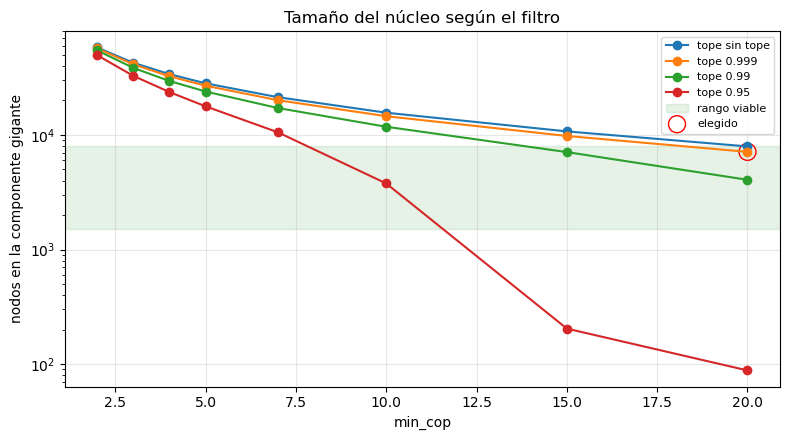

In [12]:
viables = barrido[barrido.viable & (barrido.tope != "sin tope")]
if viables.empty:
    raise ValueError("Ninguna combinación deja un núcleo entre N_MIN y N_MAX: ampliar RANGO_MIN_COP o RANGO_TOPE")
elegido = viables.sort_values(["nodos", "pct_peso"], ascending=False).iloc[0]
MIN_COP = int(elegido.min_cop)
TOPE = None if elegido.tope == "sin tope" else float(elegido.tope)
hub, e, gig = nucleo(MIN_COP, TOPE)
print(f"núcleo: min_cop = {MIN_COP}, tope = {TOPE} → {gig.sum():,} nodos, {len(e):,} aristas, {hub.sum():,} hubs retirados")

fig, ax = plt.subplots(figsize=(8, 4.5))
for t, d in barrido.groupby("tope", sort=False):
    ax.plot(d.min_cop, d.nodos, "o-", label=f"tope {t}")
ax.axhspan(N_MIN, N_MAX, color="green", alpha=.1, label="rango viable")
ax.scatter([MIN_COP], [gig.sum()], s=150, facecolors="none", edgecolors="red", label="elegido")
ax.set(xlabel="min_cop", ylabel="nodos en la componente gigante", yscale="log", title="Tamaño del núcleo según el filtro")
ax.legend(fontsize=8)
mostrar_fig("barrido_nucleo")

- **Rango viable** (`N_MIN`–`N_MAX` nodos, ≤ `E_MAX` aristas): solo con filtros fuertes

- **Sin retirar hubs**, min_cop = 20 ya es viable (7,937 nodos, 32.0% del peso)

- Pero conserva proveedores de grado 849 dentro: serían el centro de comunidades gigantes

- **Elegido:** tope = 0.999, min_cop = 20 → **7,114 nodos** y **40,957 aristas** con el **22.0%** del peso

- El núcleo describe a los competidores **muy recurrentes** (≥ 20 procesos compartidos) y deja fuera a los esporádicos

---
### **4. Peso de las aristas**

Louvain (γ = 1) sobre el núcleo con cada peso: modularidad, tamaños y cuánto se parecen entre sí y a la región dominante

In [13]:
idx_n = np.flatnonzero(gig)
nuevo = pd.Series(np.arange(len(idx_n)), index=idx_n)
en = e.assign(i=nuevo[e.i].to_numpy(), j=nuevo[e.j].to_numpy())
reg = v.loc[idx_n, "id"].map(at.set_index("id").region_dom).to_numpy()
ok = pd.notna(reg)

filas, part_peso = [], {}
for p in RANGO_PESO:
    A_p = matriz(en, len(idx_n), p)
    t0 = time.time(); lab = louvain(a_networkx(A_p)); seg = time.time() - t0
    part_peso[p] = lab
    filas.append({**resumir(A_p, lab, f"louvain ({p})", seg), "peso": p, "nmi_region": nmi(lab[ok], reg[ok])})
eleccion = pd.DataFrame(filas)
for p in RANGO_PESO:
    eleccion[f"nmi_vs_{p}"] = [nmi(part_peso[q_], part_peso[p]) for q_ in RANGO_PESO]
eleccion.round(3)

,metodo,comunidades,comunidades_grandes,pct_nodos_en_mayor,pct_nodos_en_grandes,Q,cobertura,conductancia_med,seg,peso,nmi_region,nmi_vs_binario,nmi_vs_n_coparticipa,nmi_vs_peso
0,louvain (binario),34,28,12.750,99.424,0.854,0.918,0.070,1.114,binario,0.227,1.000,0.922,0.899
1,louvain (n_coparticipa),35,29,12.932,99.438,0.865,0.930,0.057,0.680,n_coparticipa,0.232,0.922,1.000,0.924
2,louvain (peso),37,29,11.934,99.227,0.869,0.938,0.057,0.783,peso,0.220,0.899,0.924,1.000


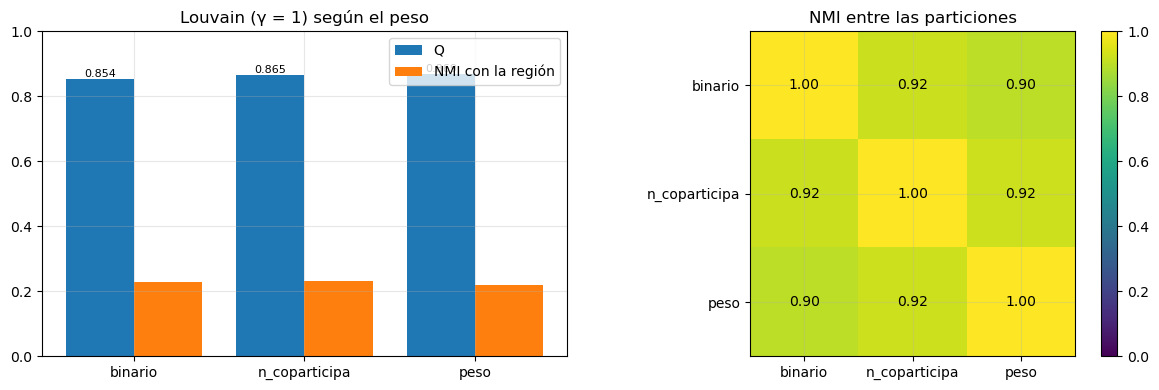

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(RANGO_PESO))
b = ax[0].bar(x - .2, eleccion.Q, .4, label="Q")
ax[0].bar(x + .2, eleccion.nmi_region, .4, label="NMI con la región")
ax[0].bar_label(b, fmt="%.3f", fontsize=8)
ax[0].set_xticks(x); ax[0].set_xticklabels(RANGO_PESO)
ax[0].set(ylim=(0, 1), title="Louvain (γ = 1) según el peso"); ax[0].legend()
M = eleccion[[f"nmi_vs_{p}" for p in RANGO_PESO]].to_numpy()
im = ax[1].imshow(M, vmin=0, vmax=1, cmap="viridis")
ax[1].set_xticks(x); ax[1].set_xticklabels(RANGO_PESO); ax[1].set_yticks(x); ax[1].set_yticklabels(RANGO_PESO)
for r in range(len(x)):
    for c in range(len(x)):
        ax[1].text(c, r, f"{M[r, c]:.2f}", ha="center", va="center", color="w" if M[r, c] < .6 else "k")
plt.colorbar(im, ax=ax[1]); ax[1].set_title("NMI entre las particiones")
mostrar_fig("eleccion_peso")

- **`binario`** trata igual coincidir en 2 procesos que en 50

- **`n_coparticipa`** premia la recurrencia; una licitación de 30 postores une 435 pares con el mismo peso que una de 3

- **`peso` (elegido):** descuenta las coincidencias en procesos masivos y da la mayor Q (**0.869** vs 0.854 binario)

- Las tres particiones se parecen (NMI **0.90–0.92**): las comunidades no son un artefacto del peso

---
### **5. Exportación a `temp/datos/`**

- `nodos.parquet`: núcleo con `idx` 0…n−1, clave, nombre, consorcio, grado en el grafo completo y atributos

- `aristas.parquet`: aristas del núcleo con `n_coparticipa` y `peso`

- `atributos.parquet`: atributos de **todos** los proveedores

- `hubs.parquet`: hubs retirados

In [15]:
nodos = (v.loc[idx_n].reset_index(drop=True).assign(idx=np.arange(len(idx_n)), grado_completo=grado[idx_n])
           .merge(at, on="id", how="left"))
nodos.to_parquet(datos_dir / "nodos.parquet", index=False)
en[["i", "j", "n_coparticipa", "peso"]].to_parquet(datos_dir / "aristas.parquet", index=False)
at.assign(grado=grado[pos[at.id].to_numpy()]).to_parquet(datos_dir / "atributos.parquet", index=False)
hubs = v[hub].assign(grado=grado[hub]).merge(at, on="id", how="left")
hubs.to_parquet(datos_dir / "hubs.parquet", index=False)
guardar_config({"min_cop": MIN_COP, "tope": TOPE, "peso": PESO, "n": int(len(idx_n)), "m": int(len(en)),
                "aristas_dobles": bool(dobles),
                "umbral_hub": float(grado[hub].min()) if hub.any() else None,
                "grado_hub": "grado en el grafo completo (aristas con ≥ 2 procesos)",
                "n_hubs": int(hub.sum())})
print(f"temp/datos: nodos ({len(nodos):,}), aristas ({len(en):,}), atributos ({len(at):,}), hubs ({len(hubs):,}), config.json")
print(f"consorcios: grafo completo {pct_si(at.es_consorcio):.1f}% | núcleo {pct_si(nodos.es_consorcio):.1f}% | "
      f"hubs {pct_si(hubs.es_consorcio):.1f}%")

temp/datos: nodos (7,114), aristas (40,957), atributos (60,213), hubs (61), config.json
consorcios: grafo completo 0.7% | núcleo 0.6% | hubs 0.0%


---
### **6. Escritura de resultados**

In [16]:
escritos = guardar_tablas({"resumen_grafo": resumen, "atributos_cobertura": cobertura, "barrido_nucleo": barrido,
                           "eleccion_peso": eleccion,
                           "grado_completo": g.groupby("grado").size().reset_index(name="nodos")})

Escrito en 05_Comunidad/temp/a_grafo/: resumen_grafo, atributos_cobertura, barrido_nucleo, eleccion_peso, grado_completo


#### a. Verificación

In [17]:
verificar_salidas(escritos)
A_n = matriz(en, len(idx_n), PESO)
assert connected_components(A_n, directed=False)[0] == 1, "el núcleo no es conexo"
assert N_MIN <= len(idx_n) <= N_MAX and len(en) <= E_MAX, "el núcleo no respeta los límites"
pares = np.c_[np.minimum(en.i, en.j), np.maximum(en.i, en.j)]
assert len(np.unique(pares, axis=0)) == len(en), "hay aristas repetidas"
lab = part_peso[PESO]
q_nx = nx.community.modularity(a_networkx(A_n), [set(np.flatnonzero(lab == c)) for c in np.unique(lab)], weight="weight")
assert abs(modularidad(A_n, lab) - q_nx) < 1e-9, "la modularidad propia no coincide con networkx"
print("núcleo conexo | sin aristas repetidas | modularidad propia = networkx")

OK: 5 tablas (parquet + json) | 4 figuras: atributos_proveedores, barrido_nucleo, eleccion_peso, estructura_grafo


núcleo conexo | sin aristas repetidas | modularidad propia = networkx


---
### **7. Cerrar sesión**

In [18]:
spark.stop()